# Image quality classification on CAMUS with a pre-trained CNN

In this notebook, we will firstly go through a refresher on Machine Learning and Deep Learning, specifically in the medical context, seeing its dynamics and differences with respect to more classical approaches. Then, we will see an example of classification of echocardiographic images that could serve as a basis for your second part of the project!

## ML 101: why deep learning in medical imaging?

Consider the task you'll be handling, that is the **left ventricular (LV) volume** estimation from an echo image. There are two ways to get from the image to the number:

- **Hand-crafted features:** a person decides what matters in the image and designs the processing that extracts it (filtering, edge detection, segmentation rules). A simple ML model (a classifier or a regressor) is then trained on those measurements. Every rule must be designed and tuned by hand, so this approach fails to scale as datasets grow and clinical variability increases (different patients, scanners, acoustic windows, image quality).
- **Representation learning:** a deep neural network receives the raw pixels and learns by itself which visual features are useful for the task. The whole chain, from the pixels to the output, is trained together (**end-to-end**).

The key change is that features are no longer designed, but *learned from data*. The price is that the model is only as good as its data: it needs many expert annotations, representative of the patients it will be used on.

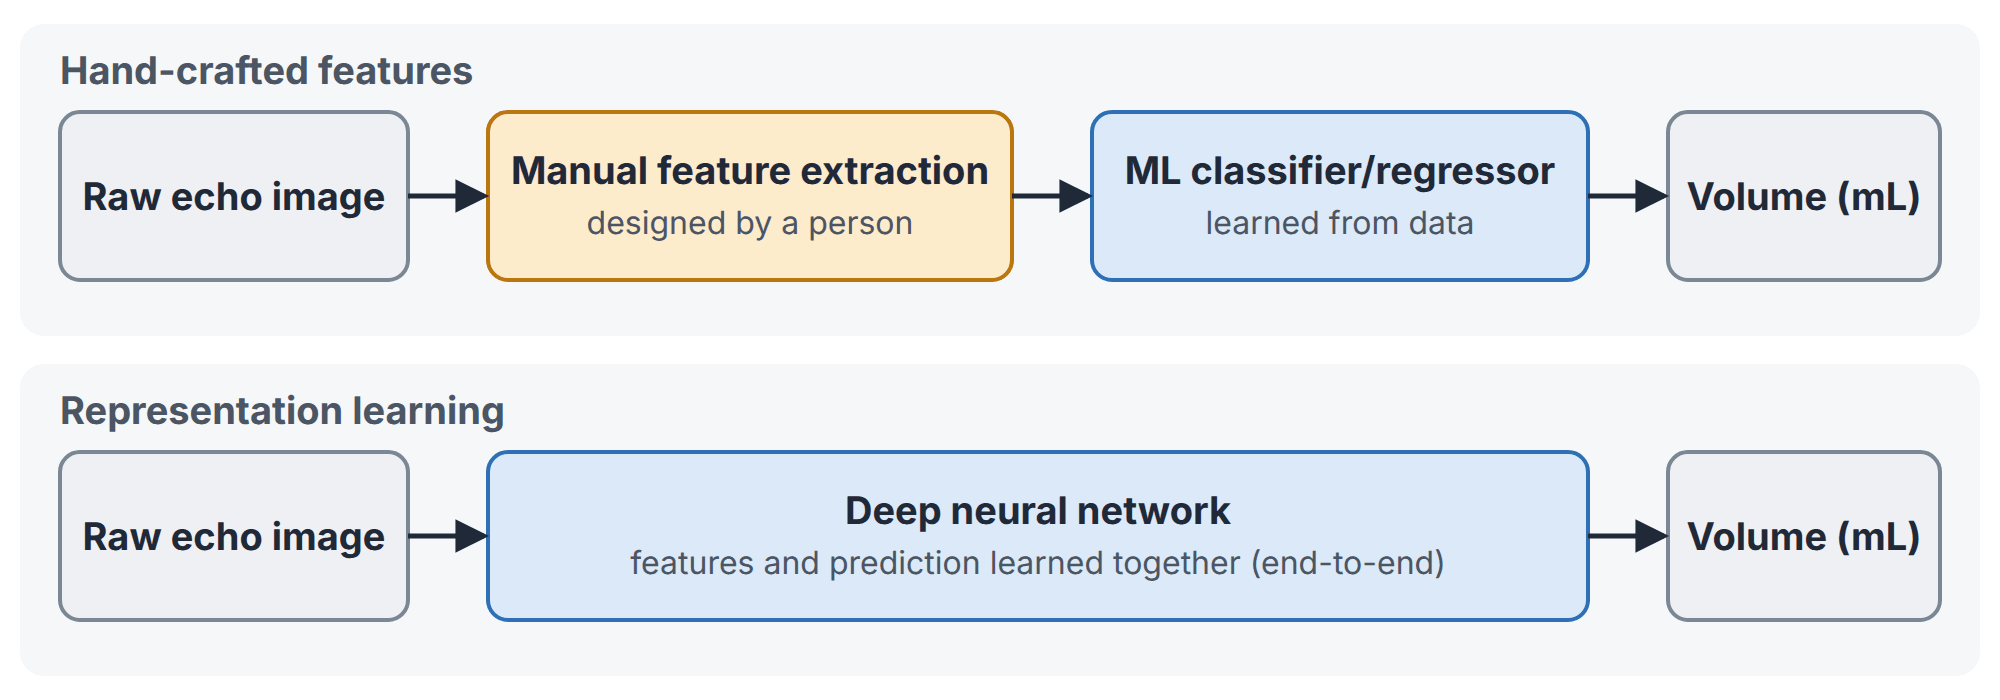

*Hand-crafted features vs representation learning: a single network replaces the two separate steps. Figure created with AI assistance.*

## ML 101: training, validation and test sets

A useful model must **generalize**, i.e., work on data it has never seen, instead of simply memorizing its training examples. Preparing for an exam is a good analogy, and it explains why the data are split into three sets:

- **Training set (practice exams):** the material the student goes through again and again. One full pass over it is an **epoch**. The model learns from this set only.
- **Validation set (self-assessment exam):** kept out of the study material and checked periodically. If practice scores keep improving while self-assessment scores stall or get worse, the student is memorizing answers instead of learning general principles: this is **overfitting**. We also use this set to make our choices, such as when to stop training.
- **Test set (final exam):** locked away until the end and evaluated exactly once, when all the choices are final. The validation set has influenced those choices, so only the test set gives an honest estimate of real-world performance.

**In echocardiography**, the real-world question is whether the volume estimated for a *new patient* can be trusted. The split must therefore be done **by patient**: if frames of the same patient end up in both the training and the test set, the final exam contains questions the student has already seen, and the score looks better than it really is.

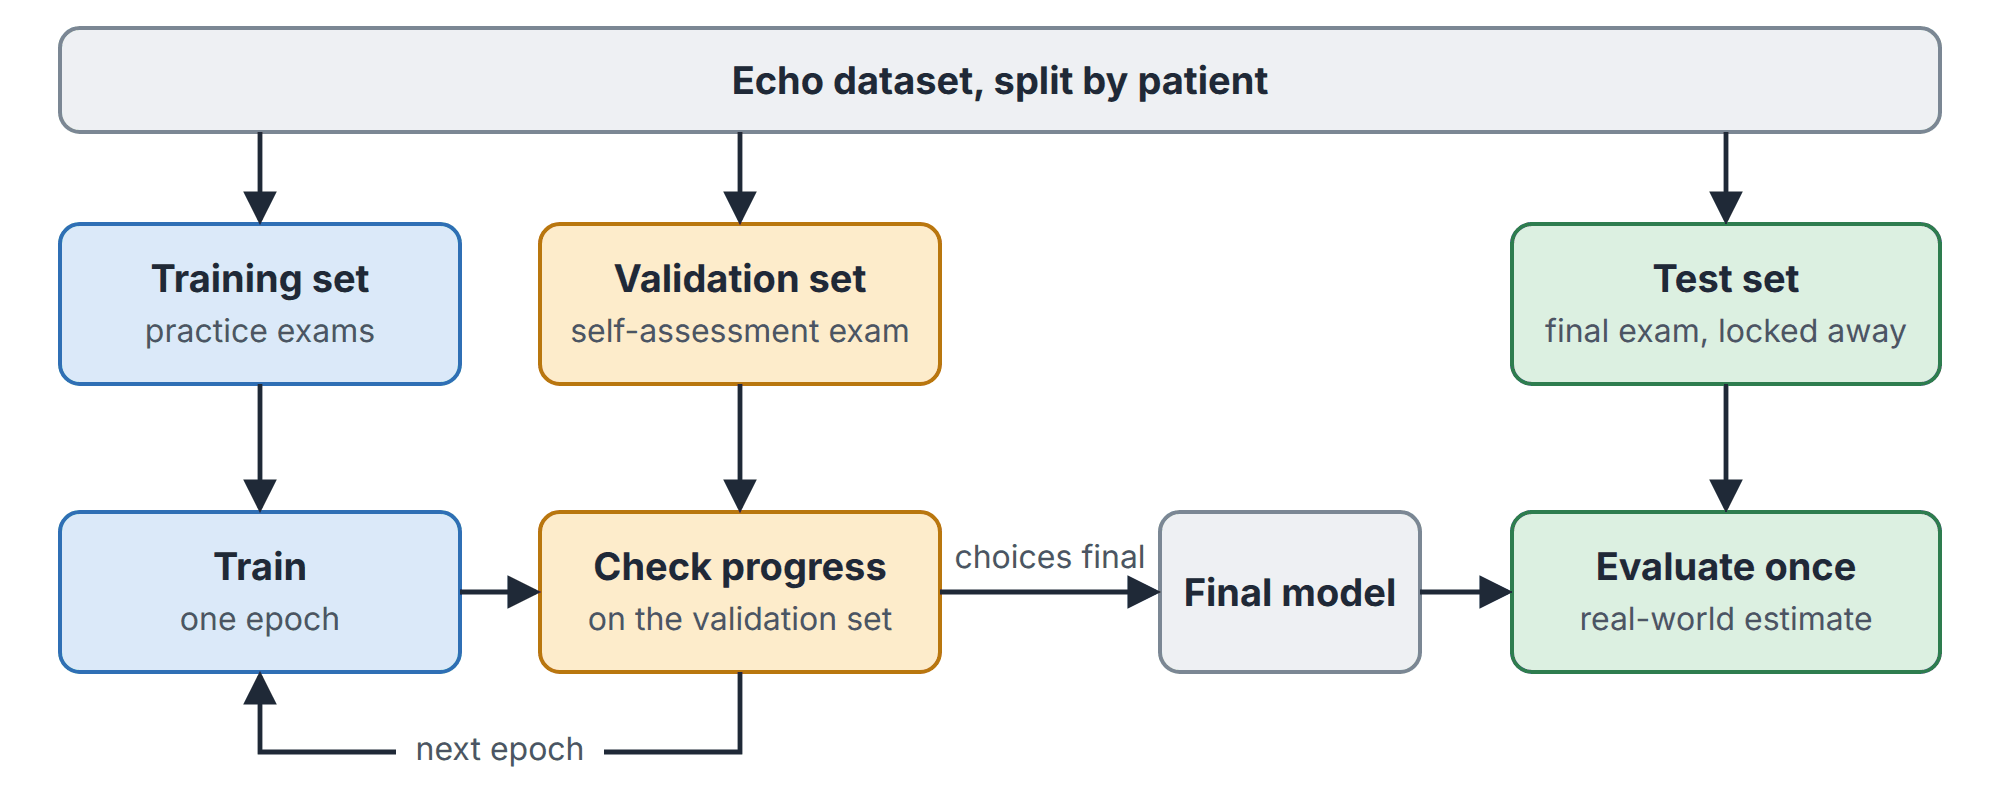

*Dataset split and validation monitoring during training. Figure created with AI assistance.*

## ML 101: how does the model learn?

A neural network is a long chain of simple operations controlled by millions of numbers, the **weights**. Training means searching for the weights that bring its predictions closer to the expert annotations. Images are processed in small groups called **batches**, and the same four steps are repeated for each batch:

1. **Forward pass:** the batch of echo images flows through the network, which outputs a predicted volume for each image.
2. **Loss function:** the predictions are compared with the expert ground truth. The loss condenses the error into a single number, which training tries to make as small as possible.
3. **Backpropagation:** moving backward from the loss through the network, we compute the **gradient** of each weight, i.e., how the loss would change if that weight changed slightly. No weight has changed yet.
4. **Weight update:** the **optimizer** uses the gradients to move each weight by a small step in the direction that reduces the loss. The **learning rate** sets the size of the step.

Think of walking downhill in the fog: you cannot see the valley, but you can feel the slope under your feet (the gradient) and take a small step (the learning rate) in the direction that goes down.

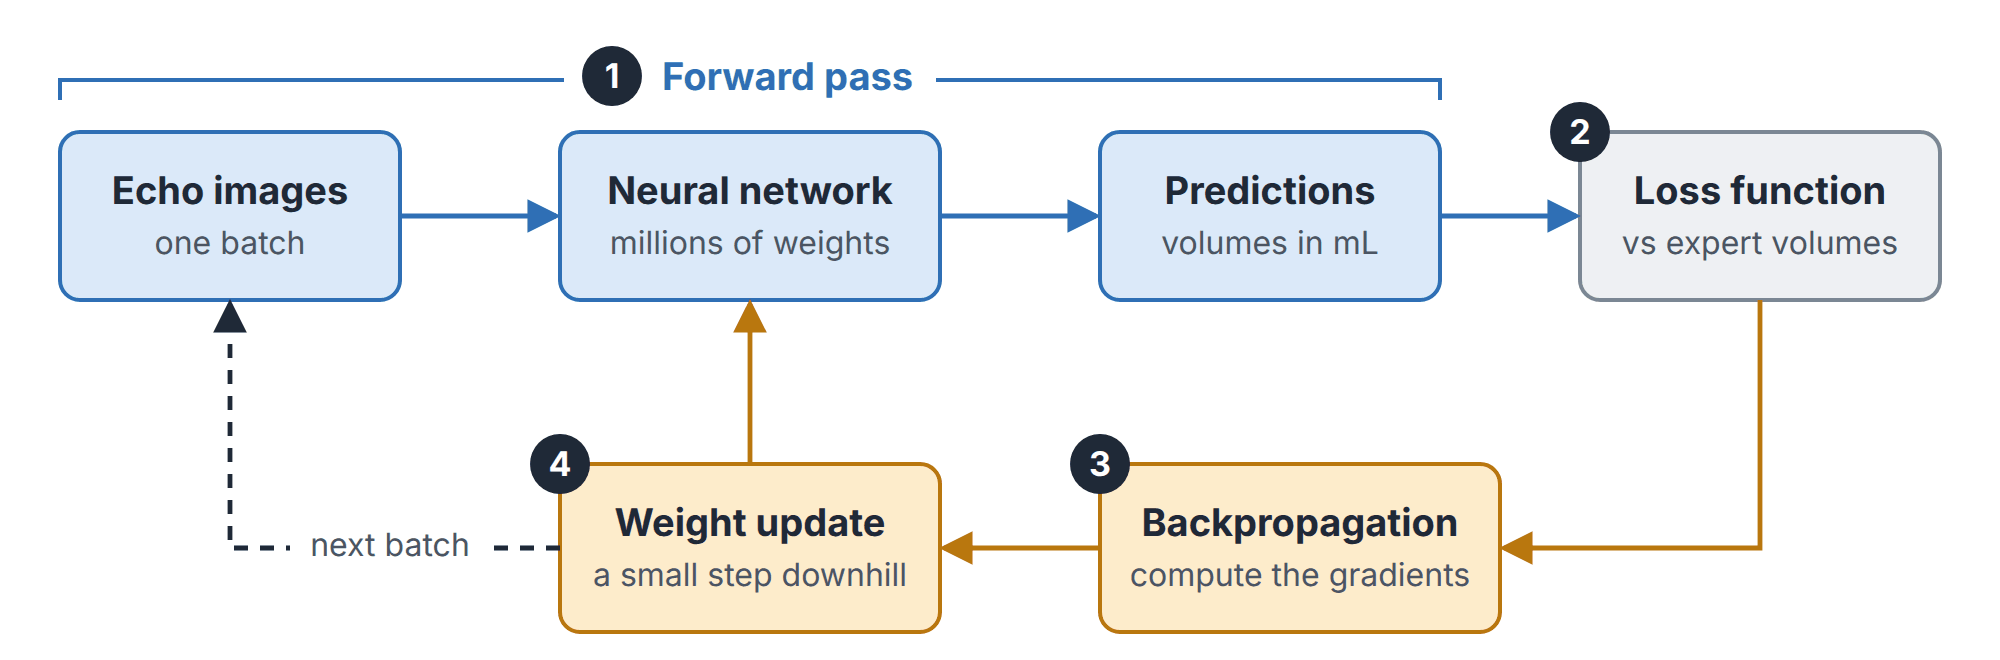

*The training loop, with the same four steps listed above. Figure created with AI assistance.*

## From ML 101 to this notebook

This year project can be tackled either as a **regression** (i.e., predicting a continuous value) or a **classification** (i.e., predicting a discrete label representing a volume level) problem.

To support you, we provide in this notebook a complete example of how to approach the classification problem. The model picks a label from a fixed list (e.g., `Good` or `Poor`), representing the echocardiographic frame quality.

Everything seen so far applies to both: the three data sets, the four-step training loop and the risk of overfitting are the same. Only two details change:

- **What the network outputs:** one number for regression, one score per label for classification.
- **How the error is measured:** how far the prediction is from the expert volume for regression, how little confidence the model gives to the correct label for classification.

## 0. Setup

In [ ]:
import os

IN_KAGGLE = False
if os.environ.get("KAGGLE_URL_BASE", ""):
    IN_KAGGLE = True
print(IN_KAGGLE)

In [ ]:
if IN_KAGGLE:
    %pip install pydicom torchinfo

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import pydicom
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary
from torchvision.models import resnet18, ResNet18_Weights

from scipy.ndimage import correlate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
    recall_score,
)

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Device:", DEVICE)

The following cell copies code files (e.g., custom `.py` modules) from a previous notebook output into your current working directory (`/kaggle/working`) so that your directory structure remains intact across sessions.

If you haven't attached your previous notebook output yet, follow these steps:

1. **Save your previous notebook version:** Ensure your source notebook was saved via **Save Version** ➔ **Quick Save** (or **Save & Run All**).
2. **Attach the output to this notebook:**
   - In the right-hand panel, click **+ Add Input**.
   - Navigate to **Your Work** ➔ select your target notebook ➔ click the **+** button.
3. **Verify the input path:** You should see a new folder listed under `/kaggle/input/` alongside your dataset.
4. **Update `src_dir`:** Copy the relative path of the added notebook input and update the `src_dir` path in the cell below.

In [ ]:
from pathlib import Path
import shutil

src_dir = Path("/kaggle/input/notebooks/riccardogibello11/dl-introduction")
dst_dir = Path.cwd()  # Automatically resolves to /kaggle/working

# List patterns to ignore (Notebooks, JSON, Images, Reports, outputs, etc.)
ignored_extensions = shutil.ignore_patterns(
    "*.ipynb",
    "*.json",
    "*.png",
    "*.jpg",
    "*.jpeg",
    "*.html",
    "*.csv",
    "*.parquet",
    "*.txt",
    ".ipynb_checkpoints",
    "__pycache__",
)

if src_dir.exists():
    print(f"Copying Python files from {src_dir} to {dst_dir}...")
    shutil.copytree(src_dir, dst_dir, ignore=ignored_extensions, dirs_exist_ok=True)
    print("Copy completed successfully!")
else:
    print(f"Source path {src_dir} does not exist.")

In [ ]:
# Local runs: this folder must contain the `camus` directory (change it if needed)
LOCAL_ROOT = Path.home() / "Downloads" / "release"

if IN_KAGGLE:
    DATA_ROOT = Path("/kaggle/input/datasets/riccardogibello11/camus-example/camus")
    OUTPUT_ROOT = Path("/kaggle/working")
else:
    DATA_ROOT = LOCAL_ROOT / "camus"
    OUTPUT_ROOT = LOCAL_ROOT
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"{DATA_ROOT} not found: please update LOCAL_ROOT")

# Embeddings and model weights computed by this notebook are stored here
MODELS_ROOT = OUTPUT_ROOT / "models"
MODELS_ROOT.mkdir(parents=True, exist_ok=True)

## 1. Data

In [ ]:
IMG_SIZE = 224
QUALITY_TAG = (0x0035, 0x1006)  # private DICOM tag holding the image quality
CLASSES = ["Poor", "Good"]  # Medium frames are excluded from this binary task
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
MAX_MASK_LABEL = (
    3  # CAMUS masks: 0 background, 1 LV cavity, 2 myocardium, 3 left atrium
)
SPLITS = ["train", "val", "test"]

### 1.1 Reading the DICOM files

In this notebook we only use the **clean** images. `index.csv` links the same acquisition across the sub-folders: each frame has a *clean* version, a *perturbed* version and a *mask* (the manual segmentation), and each row states whether the patient belongs to `train`, `val` or `test`.

The data are already split, but always check that each patient appears in a single split only. Otherwise, the model would be tested on patients it has already seen during training: this is a form of **data leakage**, and it overestimates the performance.

In [ ]:
index = pd.read_csv(DATA_ROOT / "index.csv")
index["patient"] = index["clean_id"].str.extract(r"(patient\d+)", expand=False)
display(index.head())
print(index["split"].value_counts())

# Each patient must belong to one split only
assert index.groupby("patient")["split"].nunique().max() == 1

The quality label is stored in a DICOM *private* tag, `(0035, 1006)`, which contains the required `Good` or `Poor` labels.

In [ ]:
def dicom_path(split, kind, file_id):
    return DATA_ROOT / split / kind / f"{file_id}.dcm"


# Inspect one file
row = index.iloc[0]
path = dicom_path(row["split"], "clean", row["clean_id"])
ds = pydicom.dcmread(path)
print(f"Path: {path}")
# Print only the private tag containing the quality label
print(f"Quality tag --> {ds.get(QUALITY_TAG)}")
print(
    "Raw value of the quality tag:",
    ds[QUALITY_TAG].value,
    "| type:",
    type(ds[QUALITY_TAG].value),
)
print("Image shape:", ds.pixel_array.shape)

### 1.2 Prepare the data

Images have different sizes, so each one is rescaled to the intensity range [0, 1] and resized to 224 x 224. This stretches the images noticeably, but it gives the network a single input format. Masks are resized in the same way, but with **nearest-neighbour interpolation**, so that label values are not blended.

The dataset for this exercise is small enough to keep in memory as `uint8`, so it can be cached in an `.npz` file (see https://numpy.org/devdocs/reference/generated/numpy.lib.npyio.NpzFile.html) and the slow DICOM reading is done only once. For larger datasets, the Datasets library can load the data on-the-fly, but it requires more implementation effort (https://huggingface.co/docs/datasets/en/index).

In [ ]:
def to_square_uint8(arr, size=IMG_SIZE):
    arr = arr.astype(np.float32)
    a = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)  # min-max to [0, 1]
    t = torch.from_numpy(a)[None, None]
    t = F.interpolate(
        t,
        size=(size, size),
        mode="bilinear",
        antialias=True,
        align_corners=False,
    )
    return (t[0, 0].clamp(0, 1) * 255).round().byte().numpy()


def mask_to_square_uint8(arr, size=IMG_SIZE):
    t = torch.from_numpy(arr.astype(np.float32))[None, None]
    t = F.interpolate(t, size=(size, size), mode="nearest-exact")
    return t[0, 0].round().byte().numpy()


def load_split(
    split: str,
) -> dict[str, np.ndarray]:
    """
    Loads images, masks, labels and patient identifiers for a given split (train, val, test)
    into memory, reading each file only once.

    Args:
        split (str): The split to load, one of "train", "val", or "test".

    Returns:
        dict[str, np.ndarray]: A dictionary containing, for the same N frames in the same order:
            - x: A numpy array of shape (N, IMG_SIZE, IMG_SIZE) containing the images.
            - mask: A numpy array of shape (N, IMG_SIZE, IMG_SIZE) containing the masks.
            - y: A numpy array of shape (N,) containing the corresponding labels as
            integers (0 for Poor, 1 for Good).
            - patient: A numpy array of shape (N,) containing the patient identifiers.
    """
    rows = index[index["split"] == split]
    imgs, masks, labels, patients = [], [], [], []
    for row in tqdm(rows.itertuples(), total=len(rows), desc=split):
        ds = pydicom.dcmread(dicom_path(split, "clean", row.clean_id))
        current_quality_idx = CLASS_TO_IDX.get(ds[QUALITY_TAG].value, None)
        if current_quality_idx is None:
            continue  # Skip the whole frame if its quality label is not in CLASSES
        mask_ds = pydicom.dcmread(dicom_path(split, "masks", row.mask_id))
        imgs.append(to_square_uint8(ds.pixel_array))
        masks.append(mask_to_square_uint8(mask_ds.pixel_array))
        labels.append(current_quality_idx)
        patients.append(row.patient)
    return {
        "x": np.stack(imgs),
        "mask": np.stack(masks),
        "y": np.array(labels, dtype=np.int64),
        "patient": np.array(patients),
    }

In [ ]:
CACHE = OUTPUT_ROOT / f"camus_{'_'.join(CLASSES).lower()}_{IMG_SIZE}.npz"
FIELDS = ("x", "mask", "y", "patient")

if CACHE.exists():
    with np.load(CACHE) as z:
        data = {s: {k: z[f"{s}_{k}"] for k in FIELDS} for s in SPLITS}
else:
    data = {s: load_split(s) for s in SPLITS}
    np.savez_compressed(
        CACHE, **{f"{s}_{k}": d[k] for s, d in data.items() for k in FIELDS}
    )

for s, d in data.items():
    assert len({len(d[k]) for k in FIELDS}) == 1, f"{s}: arrays are not aligned"
    print("=" * 40)
    print(
        f"{s}: {d['x'].shape[0]} images of shape {d['x'].shape[1:]}, "
        f"{d['y'].shape[0]} labels of type {d['y'].dtype}"
    )
print(
    "Label values found in masks:", np.unique(data["train"]["mask"])
)  # expected: 0, 1, 2, 3

In [ ]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(8, 4))
rng = np.random.default_rng(SEED)
for col, c in enumerate(CLASSES):
    # Pick a random sample in the training set for the current class
    picked_id: int = rng.choice(np.where(data["train"]["y"] == CLASS_TO_IDX[c])[0])
    axes[col].imshow(data["train"]["x"][picked_id], cmap="gray")
    axes[col].set_title(c)
    axes[col].axis("off")
plt.tight_layout()
plt.show()

### 1.3 Class distribution

Always look at the label distribution before training, and before deciding which metrics to adopt for evaluating your model.

In [ ]:
dist = pd.DataFrame(
    {
        s: pd.Series(d["y"]).map(dict(enumerate(CLASSES))).value_counts()
        for s, d in data.items()
    }
).reindex(CLASSES)
dist_percent = (100 * dist / dist.sum()).round(1)
dist = pd.concat([dist, dist_percent.add_suffix(" (%)")], axis=1)
display(dist)

Because the `Poor` class is severely underrepresented compared to the `Good` class (e.g., 98 `Good` vs. 2 `Poor`), standard accuracy is misleading:

$$\text{Acc} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$

For instance, a naive model predicting `Good` for all 100 samples achieves **Acc = 0.98** ($\text{TP}=98, \text{TN}=0, \text{FP}=2, \text{FN}=0$), hiding the fact that it misses every `Poor` image.

To evaluate imbalanced data properly, consider **Balanced Accuracy**:

$$\text{bAcc} = \frac{\text{TPR} + \text{TNR}}{2}$$

$$\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \quad \text{TNR} = \frac{\text{TN}}{\text{TN} + \text{FP}}$$

For the naive model above, $\text{TPR} = 1$ and $\text{TNR} = 0$, resulting in **bAcc = 0.5**—the exact score of random guessing.

Alternatively, use the **Macro F1 Score**:

$$\text{maF1} = \frac{F_1\text{(Good)} + F_1\text{(Poor)}}{2}$$

$$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}, \quad \text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

In the same example, $F_1\text{(Good)} \approx 0.99$ and $F_1\text{(Poor)} = 0$, yielding **maF1 ≈ 0.495** and correctly penalizing the model for ignoring the minority class.

## 2. What is a Convolutional Neural Network (CNN)? Which one to choose?

A Convolutional Neural Network (CNN) is the type of neural network that started the deep learning revolution in computer vision. It is particularly effective for image classification, object detection, and other computer vision tasks.

Instead of extracting features by manually applying filters (e.g., Sobel, Laplacian, Gaussian), a CNN learns the filters directly from the data. This is done by training the network on a (very) large dataset of labeled images, where it learns to identify the patterns that are relevant for the task at hand.

A CNN is a stack of convolutional layers: each layer convolves its input with a set of small learnable kernels, applies a non-linearity, and passes the resulting *feature maps* to the next layer. Pooling layers progressively reduce the spatial size of the feature maps.

<img src="https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/same_padding_no_strides.gif" alt="Animation of a 3 x 3 kernel sliding over an input image" width="220" style="background-color:white; padding:8px">

*A 3 x 3 kernel sliding over its input to produce a feature map. Source: V. Dumoulin and F. Visin, [conv_arithmetic](https://github.com/vdumoulin/conv_arithmetic) (MIT licence).*

<img src="https://upload.wikimedia.org/wikipedia/commons/6/63/Typical_cnn.png" alt="Diagram of a typical CNN: convolutions and subsampling followed by fully connected layers" width="700" style="background-color:white; padding:8px">

*A typical CNN: convolution and subsampling layers extract features, and fully connected layers produce the output. Source: Aphex34, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Typical_cnn.png), CC BY-SA 4.0.*

CNNs have also shown good generalization capabilities: a network trained on one dataset can often be applied to a different one with little adaptation effort. This is particularly useful in medical imaging, where labeled data are often scarce.

Out in the wild, there are many different models available. Always think about these two questions: *what was the model trained for?* and *how similar is my data to its training data?* The answers will help you decide which model to choose, and whether to transfer the knowledge of a pre-trained model to your task or train from scratch.

In this case, we'll use **ResNet-18** (see https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html), a small and fast network trained on ImageNet (1.2 million natural images, 1000 classes). Its name comes from its *residual connections*: each block adds its input back to its output, which makes deep networks easier to train.

<img src="https://d2l.ai/_images/residual-block.svg" alt="A regular block next to a residual block with a skip connection" width="380" style="background-color:white; padding:8px">

*A regular block (left) and a residual block (right). Source: Zhang et al., [Dive into Deep Learning](https://d2l.ai/chapter_convolutional-modern/resnet.html), CC BY-SA 4.0.*

<img src="https://d2l.ai/_images/resnet18-90.svg" alt="Layer-by-layer diagram of ResNet-18" width="800" style="background-color:white; padding:8px">

*The ResNet-18 architecture. Source: Zhang et al., [Dive into Deep Learning](https://d2l.ai/chapter_convolutional-modern/resnet.html), CC BY-SA 4.0.*

In [ ]:
model_pre = resnet18(weights=ResNet18_Weights.DEFAULT).to(DEVICE).eval()
print(
    summary(
        model_pre,
        input_size=(1, 3, IMG_SIZE, IMG_SIZE),
        col_names=["input_size", "output_size", "kernel_size", "num_params"],
        col_width=22,
        depth=2,  # Increase it to expand the nested BasicBlocks
        row_settings=["var_names"],  # Shows explicit variable names alongside types
        device=DEVICE,
    )
)

As you will have noticed, the model requires 3 input channels (recall that it was trained on RGB images). This can be fixed by repeating the single channel of the echocardiographic images 3 times. In addition, images must be normalized, either with the mean and standard deviation of the ImageNet training set or with those of the CAMUS training set. In this notebook, we use the ImageNet statistics, which are: mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225].

In [ ]:
IM_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def to_model_input(imgs_u8, masks_u8=None):
    # imgs_u8: (B, H, W) uint8  ->  (B, 3, H, W) float, or (B, 4, H, W) if masks are given
    x = torch.from_numpy(imgs_u8).float().div(255).unsqueeze(1)
    x = x.repeat(1, 3, 1, 1)
    x = (x - IM_MEAN) / IM_STD
    if masks_u8 is not None:
        m = torch.from_numpy(masks_u8).float().div(MAX_MASK_LABEL).unsqueeze(1)
        x = torch.cat([x, m], dim=1)
    return x


# Take the first 4 images from the training set for demonstration
xb = to_model_input(data["train"]["x"][:4])
print(xb.shape, xb.mean().item(), xb.std().item())

## 3. Looking inside the network

Before adapting the network to our task, let's see what it has learned on ImageNet.

### 3.1 The first layer: learned filters

`conv1` has 64 kernels of size 7 x 7 x 3 (7 x 7 pixels, 3 input channels), so each kernel can be displayed as a small RGB image.

In [ ]:
def show_kernels(kernels, ncols=16, titles=None, title=None, cell=0.9):
    # kernels: gray (n, k, k) or RGB (n, k, k, 3). Each one is rescaled to its own min-max range
    n = len(kernels)
    nrows = int(np.ceil(n / ncols))
    height = cell * (1.4 if titles else 1.0)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(ncols * cell, nrows * height), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for i, (ax, k) in enumerate(zip(axes.ravel(), kernels)):
        k = (k - k.min()) / (k.max() - k.min() + 1e-8)
        # 'nearest' prevents smooth blurring on small matrices (e.g. 7 x 7)
        ax.imshow(k, cmap="gray", interpolation="nearest")
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


w1 = model_pre.conv1.weight.detach().cpu().permute(0, 2, 3, 1).numpy()
show_kernels(w1, title="ResNet-18 conv1 kernels")

Many kernels are **oriented edge detectors** (light-to-dark transitions at different angles), some are **Gabor-like** (an oriented sinusoid under a Gaussian envelope), and some are **colour blobs**. In other words, the network has learned spatial filters that extract useful low-level features, such as edges and textures, from the input images.

Our images are gray, and the same values are repeated on the 3 channels. Each colour kernel therefore acts as a single gray kernel: let's compute these kernels and compare them with classical filters.

In [ ]:
def effective_gray_kernels(conv_weight):
    # (n, 3, k, k) -> (n, k, k): equivalent single-channel kernel for a gray image repeated on 3 channels
    return (conv_weight.detach().cpu() / IM_STD.view(1, 3, 1, 1)).sum(dim=1).numpy()


w1_gray = effective_gray_kernels(model_pre.conv1.weight)
print(w1_gray.shape)
show_kernels(
    w1_gray,
    titles=[f"#{i}" for i in range(len(w1_gray))],
    title="ResNet-18 conv1: grayscale-equivalent 7 x 7 kernels (ImageNet)",
)

In [ ]:
K = 7
r = np.arange(K) - K // 2
X, Y = np.meshgrid(r, r)  # X grows to the right, Y grows downwards
R2 = X**2 + Y**2

# Sobel: derivative along one axis, smoothing along the other
deriv = np.array([-1, -4, -5, 0, 5, 4, 1], dtype=float)
smooth = np.array([1, 6, 15, 20, 15, 6, 1], dtype=float)
sobel_x = np.outer(
    smooth, deriv
)  # responds to vertical edges (intensity changes along x)
sobel_y = sobel_x.T  # responds to horizontal edges

# Gaussian
sigma = 1.2
gauss = np.exp(-R2 / (2 * sigma**2))
gauss /= gauss.sum()

# Laplacian of Gaussian: negative centre, positive surround, zero sum
log = -(1 - R2 / (2 * sigma**2)) * np.exp(-R2 / (2 * sigma**2))
log -= log.mean()


def gabor_7x7(theta, sigma=1.5, freq=0.25):
    # Cosine of spatial frequency `freq` (cycles/pixel) along direction theta, under a Gaussian envelope
    xr = X * np.cos(theta) + Y * np.sin(theta)
    yr = -X * np.sin(theta) + Y * np.cos(theta)
    g = np.exp(-(xr**2 + yr**2) / (2 * sigma**2)) * np.cos(2 * np.pi * freq * xr)
    return g - g.mean()


classical = {
    "Sobel x": sobel_x,
    "Sobel y": sobel_y,
    "Laplacian (LoG)": log,
    "Gaussian": gauss,
}
for deg in [0, 45, 90, 135]:
    classical[f"Gabor {deg}°"] = gabor_7x7(np.deg2rad(deg))

assert all(k.shape == (K, K) for k in classical.values())
show_kernels(
    list(classical.values()),
    ncols=8,
    titles=list(classical.keys()),
    title="Hand-designed 7 x 7 kernels",
    cell=1.6,
)

We now apply the hand-designed kernels, and four `conv1` kernels that resemble them, to the same frame. The first row shows the classical filters, the second row the raw `conv1` output, and the third row the same maps after batch normalization and ReLU, which is what the next layer actually receives.

In [ ]:
# Example frame (change the index to look at other frames)
example = data["train"]["x"][0]
x_ex = to_model_input(example[None]).to(DEVICE)

# Hooks: store the output of selected blocks during a forward pass
activations = {}


def save_activation(name):
    def hook(module, inputs, output):
        activations[name] = output

    return hook


BLOCKS = ["conv1", "layer1", "layer2", "layer3", "layer4"]
hooks = [
    getattr(model_pre, b).register_forward_hook(save_activation(b)) for b in BLOCKS
]
with torch.no_grad():
    model_pre(x_ex)
for h in hooks:
    h.remove()

img = example.astype(float) / 255
# conv1 channels that resemble Sobel x, Sobel y, Gaussian, Gabor 45 deg (picked by eye, change freely)
CHANNELS = [14, 26, 37, 47]
NAMES = ["Sobel x", "Sobel y", "Gaussian", "Gabor 45°"]

raw = activations["conv1"][0].detach().cpu()  # conv1 output, before BN and ReLU
with torch.no_grad():
    relu_maps = F.relu(model_pre.bn1(activations["conv1"]))[0].detach().cpu()


def show_signed(ax, a):
    # Maps with a relevant negative part (edge filters) are shown on a scale symmetric around zero;
    # all-positive maps (low-pass filters) are shown with the usual min-max scale
    a = np.asarray(a)
    if a.min() < -0.2 * a.max():
        m = np.percentile(np.abs(a), 99.5)
        ax.imshow(a, cmap="gray", vmin=-m, vmax=m)
    else:
        ax.imshow(a, cmap="gray")


fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row_idx in range(3):
    axes[row_idx, 0].imshow(img, cmap="gray")
    axes[row_idx, 0].set_title("Echo frame")
for j, (name, c) in enumerate(zip(NAMES, CHANNELS), start=1):
    # CNN layers compute a cross-correlation, so we use correlate (not convolve) for a fair comparison
    show_signed(axes[0, j], correlate(img, classical[name]))
    axes[0, j].set_title(name)
    show_signed(axes[1, j], raw[c])
    axes[1, j].set_title(f"conv1 #{c} (signed output)")
    axes[2, j].imshow(relu_maps[c], cmap="gray")
    axes[2, j].set_title(f"conv1 #{c} (after BN + ReLU)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3.2 Deeper layers: feature maps become abstract

As the layers go deeper, the learned filters become harder to interpret, because they combine the filters of the previous layers. We now display the first 8 feature maps of every block for the same frame. Notice how the spatial size shrinks and the maps stop looking like filtered versions of the image: deeper units respond to larger, more complex patterns.

In [ ]:
fig, axes = plt.subplots(len(BLOCKS), 8, figsize=(16, 2.2 * len(BLOCKS)))
for col, b in enumerate(BLOCKS):
    a = activations[b][0]
    for k in range(8):
        axes[col, k].imshow(a[k].detach().cpu(), cmap="viridis")
        axes[col, k].axis("off")
    axes[col, 0].set_title(f"{b}: {tuple(a.shape)}", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 4. How can we adapt the pre-trained network to our task?

First, the model head (i.e., the last fully-connected layer, which outputs the 1000 ImageNet classes) is replaced with a new one for our 2 classes (`Poor`, `Good`). Then, the model can be trained in two different ways:
- **Frozen network as a feature extractor**: the pre-trained weights are not updated, and only the new head (either a simple logistic regression or a small neural network) is trained. This is fast and requires less data, but it relies on features learned from ImageNet, which might not be the best for echocardiographic images.
- **Fine-tuning the whole network**: the pre-trained weights are updated along with the new head. This is slower and requires more data, but the model can learn features that are more relevant for echocardiographic images.

<img src="https://d2l.ai/_images/finetune.svg" alt="Layers copied from a source model into a target model, with a new output layer" width="500" style="background-color:white; padding:8px">

*Fine-tuning: the layers are copied from the source model, and a new output layer is trained for the target task. Source: Zhang et al., [Dive into Deep Learning](https://d2l.ai/chapter_computer-vision/fine-tuning.html), CC BY-SA 4.0.*

Be careful with your dataset size! Neural networks have a large number of parameters, and if the dataset is too small the model might **overfit** (i.e., it memorizes the training data, getting good scores on it but performing poorly on unseen data). In this case, it is better to freeze the pre-trained model and train only the new head.

In the following, the **validation** set is used to make all the choices (hyper-parameters, best epoch). The **test** set is kept aside until Section 6, where the final models are compared.

### 4.1 Using the frozen network as a feature extractor

We remove the last fully-connected layer (`fc`) and use the 512-dimensional vector coming out of global average pooling as a descriptor of the image (an *embedding*). A standard classifier is then trained on these descriptors. No gradient flows into the CNN, so this is fast. Note that the features are still learned rather than hand-designed, but on ImageNet instead of our data.

In [ ]:
backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE).eval()


@torch.inference_mode()
def extract_embeddings(
    model,
    imgs,
    split: str,
    bs=128,
) -> np.ndarray:
    embeddings_file_path = MODELS_ROOT / f"embeddings_{split}.npy"
    if embeddings_file_path.exists():
        print(f"Loading cached embeddings from {embeddings_file_path}")
        return np.load(embeddings_file_path)

    out = []
    for s in range(0, len(imgs), bs):
        out.append(model(to_model_input(imgs[s : s + bs]).to(DEVICE)).cpu())
    embeddings = torch.cat(out).numpy()
    np.save(embeddings_file_path, embeddings)
    return embeddings

In [ ]:
emb = {s: extract_embeddings(backbone, d["x"], split=s) for s, d in data.items()}
print({s: e.shape for s, e in emb.items()})

In [ ]:
def report(y_true, y_pred, title):
    print(title)
    print(f"  balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.3f}")
    print(f"  macro F1:          {f1_score(y_true, y_pred, average='macro'):.3f}")

In [ ]:
def fit_logreg(C):
    # As mentioned before, setting the class_weight to "balanced" helps to handle the class imbalance in the dataset.
    # This means that the algorithm will adjust the weights inversely proportional to class frequencies in the input
    # data, which can help improve performance on underrepresented classes.
    # The C parameter is the inverse of regularization strength: a smaller C value specifies stronger regularization,
    # which can help prevent overfitting, especially in cases where the dataset is small or imbalanced.
    # The pipeline fits the scaler on the training set only, and applies it unchanged to any other split.
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced", C=C),
    )
    return clf.fit(emb["train"], data["train"]["y"])


report(
    data["val"]["y"],
    fit_logreg(C=0.1).predict(emb["val"]),
    "Frozen ResNet-18 + logistic regression, C=0.1 (validation)",
)

`C` is a hyper-parameter (i.e., a parameter that is not learned from the data but is set by the user), so it must be chosen on the **validation** set, never on the test set.

The chosen model is trained on the training set only, exactly like the networks below, so that the final comparison is fair.

In [ ]:
val_baccs = {}
for C in [0.001, 0.01, 0.1, 1.0]:
    pred_val = fit_logreg(C).predict(emb["val"])
    val_baccs[C] = balanced_accuracy_score(data["val"]["y"], pred_val)
    print(f"C={C:<6} val balanced acc = {val_baccs[C]:.3f}")

best_C = max(val_baccs, key=val_baccs.get)
print("=" * 40)
print(f"Best C={best_C}, val balanced acc = {val_baccs[best_C]:.3f}")

clf_frozen = fit_logreg(best_C)

### 4.2 Fine-tuning on our downstream task

To achieve better performance on a specific task, the CNN weights can be updated as well. First, we match the model head to the new task by adding a new layer with 2 outputs.

Training is organized in **epochs** (one epoch means that the entire training set has been "seen" by the network once) and **batches** (the samples "seen" at each training step). At each step:

1. **Forward pass**: the model computes its output (e.g., the class probabilities) for the batch.
2. **Loss**: the output is compared with the ground truth labels. For this classification task we use the **cross-entropy loss** (see https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), which is small when the model gives a high probability to the correct class.
3. **Backward pass**: the **gradients** are computed, i.e., the partial derivatives of the loss with respect to the model parameters. They tell how the loss changes with each parameter, and thus identify the direction of steepest descent.
4. **Update**: the parameters take a step in that direction. The **learning rate** is the hyper-parameter that controls the size of this step.

The learning rate of the pre-trained layers is usually small (here, 1e-5) to avoid destroying the pre-trained kernels. The new layer starts from random weights, so it can use a larger one (here, 1e-4).

In presence of data scarcity, it is also common to resort to **data augmentation**, which artificially increases the size of the training set by applying random transformations (e.g., rotations, flips, brightness/contrast adjustments) to the original images. This can improve generalization and reduce overfitting. However, transformations should be relevant to the task: in echocardiography, for example, flips or rotations might not be appropriate, as the orientation of the view is informative. Applied more often to the under-represented classes, augmentation can also help with class imbalance.

In [ ]:
def augment(x):
    # Random gain and offset on the image channels only (the first 3)
    b = x.shape[0]
    gain = 1 + 0.4 * (torch.rand(b, 1, 1, 1) - 0.5)
    bias = 0.4 * (torch.rand(b, 1, 1, 1) - 0.5)
    x[:, :3] = x[:, :3] * gain + bias
    return x

In [ ]:
def build_resnet18(
    in_channels=3,
    n_classes=len(CLASSES),
):
    m = resnet18(weights=ResNet18_Weights.DEFAULT)
    if in_channels != 3:
        # Extra input channels (used in Section 5): copy the pre-trained kernels for the first 3
        # channels and initialise the new ones with the average kernel
        old = m.conv1
        new = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        with torch.no_grad():
            new.weight[:, :3] = old.weight
            new.weight[:, 3:] = old.weight.mean(dim=1, keepdim=True)
        m.conv1 = new
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m

In [ ]:
def run_epoch(
    model,
    split,
    use_mask=False,
    optimizer=None,
    class_weights=None,
    bs=32,
):
    train = optimizer is not None
    model.train(train)
    d = data[split]
    order = np.random.permutation(len(d["x"])) if train else np.arange(len(d["x"]))
    total_loss, preds = 0.0, np.zeros(len(order), dtype=np.int64)
    for s in range(0, len(order), bs):
        idx = order[s : s + bs]
        x = to_model_input(d["x"][idx], d["mask"][idx] if use_mask else None)
        if train:
            x = augment(x)
        x, y = x.to(DEVICE), torch.from_numpy(d["y"][idx]).to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = model(x)
            loss = F.cross_entropy(logits, y, weight=class_weights)
        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * len(idx)
        # Store each prediction at its original position, so that it matches d["y"]
        preds[idx] = logits.argmax(1).cpu().numpy()
    return total_loss / len(order), preds

In [ ]:
def fit(
    model,
    epochs=8,
    lr_backbone=1e-5,
    lr_head=1e-4,
    use_mask=False,
    model_name: str = "model",
):
    model.to(DEVICE)
    best_path = MODELS_ROOT / f"best_{model_name}.pth"
    history_path = MODELS_ROOT / f"best_{model_name}_history.npy"

    # Skip the training if this model is already available
    if best_path.exists() and history_path.exists():
        print(f"Loading cached model from {best_path}")
        model.load_state_dict(torch.load(best_path, map_location=DEVICE))
        return np.load(history_path)

    y_tr, y_va = data["train"]["y"], data["val"]["y"]

    # Compute class weights to handle class imbalance
    counts = np.bincount(y_tr, minlength=len(CLASSES))
    weights = torch.tensor(
        len(y_tr) / (len(CLASSES) * counts),
        dtype=torch.float32,
        device=DEVICE,
    )
    for c, w in zip(CLASSES, weights):
        print(f"{c}: {w:.3f}")

    head = list(model.fc.parameters())
    backbone_params = [
        p for n, p in model.named_parameters() if not n.startswith("fc.")
    ]
    # Set up the optimizer with different learning rates for the backbone and head
    # as they have different learning dynamics (e.g., for backbone, small adjustments,
    # for head, larger adjustments)
    opt = torch.optim.Adam(
        [
            {"params": backbone_params, "lr": lr_backbone},
            {"params": head, "lr": lr_head},
        ]
    )

    history, best = [], -1
    for ep in range(1, epochs + 1):
        tr_loss, tr_pred = run_epoch(model, "train", use_mask, opt, weights)
        va_loss, va_pred = run_epoch(model, "val", use_mask, None, weights)
        tr_bacc = balanced_accuracy_score(y_tr, tr_pred)
        va_bacc = balanced_accuracy_score(y_va, va_pred)
        history.append((tr_loss, va_loss, tr_bacc, va_bacc))
        print(
            f"epoch {ep:2d} | train loss {tr_loss:.3f} bacc {tr_bacc:.3f} | "
            f"val loss {va_loss:.3f} bacc {va_bacc:.3f}"
        )
        # Always store your model's state_dict when you find a new best validation score
        if va_bacc > best:
            best = va_bacc
            torch.save(model.state_dict(), best_path)

    # The model now holds the weights of the last epoch: restore those of the best one
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    # Cache the history for the next iterations if this is rerun
    history = np.array(history)
    np.save(history_path, history)
    return history


def plot_history(h):
    epochs = np.arange(1, len(h) + 1)
    best_epoch = epochs[h[:, 3].argmax()]
    _, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(epochs, h[:, 0], label="train")
    ax[0].plot(epochs, h[:, 1], label="val")
    ax[0].set_title("Loss")
    ax[1].plot(epochs, h[:, 2], label="train")
    ax[1].plot(epochs, h[:, 3], label="val")
    ax[1].set_title("Balanced accuracy")
    for a in ax:
        a.axvline(best_epoch, color="gray", linestyle="--", label="best val epoch")
        a.set_xlabel("epoch")
        a.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
model_ft = build_resnet18(in_channels=3)
hist_ft = fit(model_ft, epochs=8)
plot_history(hist_ft)

Check the curves: if the training metric keeps improving while the validation metric stalls or degrades, the network is overfitting. With about 900 training images and 11 million parameters this can happen quickly, which is also why the frozen network of Section 4.1 is a useful reference.

The model we keep is the one from the best validation epoch (dashed line), not the one from the last epoch.

In [ ]:
report(
    data["val"]["y"],
    run_epoch(model_ft, "val")[1],
    "Fine-tuned ResNet-18, image only (validation)",
)

## 5. Using additional information as input

So far, the network has used only the pixels of the image to decide the quality label. However, the CAMUS dataset also provides manual segmentation **masks** of the left ventricle cavity, the myocardium and the left atrium. Can this anatomical information help?

You can pick different strategies to include it in the input of the network. The simplest option is *early fusion*: stack the mask as an additional input channel (a fourth one). The first model layer then needs 4 input channels. We handle this in `build_resnet18(in_channels=4)` defined above: the pre-trained kernels are kept for the 3 image channels, and the kernels of the new channel are initialised with the average of the pre-trained kernels. This is not the only option, and you can explore other strategies by modifying the first layers of the network yourself.

IMPORTANT: In a real deployment the mask would come from a segmentation network, with its own errors, so results with manual masks are an upper bound.

Before training, always check on a few examples that each mask sits on the right image.

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
rng = np.random.default_rng(SEED)
train = data["train"]
for row_idx, c in enumerate(CLASSES):
    ids = rng.choice(np.where(train["y"] == CLASS_TO_IDX[c])[0], 2, replace=False)
    for k, i in enumerate(ids):
        axes[row_idx, 2 * k].imshow(train["x"][i], cmap="gray")
        axes[row_idx, 2 * k].set_title(c)
        axes[row_idx, 2 * k + 1].imshow(train["x"][i], cmap="gray")
        axes[row_idx, 2 * k + 1].imshow(
            np.ma.masked_equal(train["mask"][i], 0),
            cmap="jet",
            alpha=0.5,
            vmin=0,
            vmax=MAX_MASK_LABEL,
        )
        axes[row_idx, 2 * k + 1].set_title(f"{c} + mask")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
model_mask = build_resnet18(in_channels=4)
hist_mask = fit(model_mask, epochs=8, use_mask=True, model_name="masked_model")
plot_history(hist_mask)

In [ ]:
report(
    data["val"]["y"],
    run_epoch(model_mask, "val", use_mask=True)[1],
    "Fine-tuned ResNet-18, image + mask (validation)",
)

## 6. Comparison on the test set and discussion

All the choices have been made on the validation set, so we can now evaluate the three models, **once**, on exactly the same test frames. All of them were trained on the training set only.

Next to each balanced accuracy we report a 95% **confidence interval**, obtained with the bootstrap: we repeatedly resample the test *patients* with replacement and recompute the score. Patients are resampled, rather than frames, because frames of the same patient are not independent.

In [ ]:
def compute_metrics(y_true, y_pred):
    return {
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Recall Poor": recall_score(y_true, y_pred, pos_label=CLASS_TO_IDX["Poor"]),
        "Recall Good": recall_score(y_true, y_pred, pos_label=CLASS_TO_IDX["Good"]),
    }


def bootstrap_ci(y_true, y_pred, patients, n_boot=2000):
    # The same seed gives every model the same resamples, so the intervals are comparable
    rng = np.random.default_rng(SEED)
    frames = {p: np.where(patients == p)[0] for p in np.unique(patients)}
    ids = list(frames)
    scores = []
    for _ in range(n_boot):
        idx = np.concatenate([frames[p] for p in rng.choice(ids, len(ids))])
        scores.append(balanced_accuracy_score(y_true[idx], y_pred[idx]))
    return np.percentile(scores, [2.5, 97.5])


def compare_models(predictions, split="test"):
    y, patients = data[split]["y"], data[split]["patient"]
    rows = {}
    for name, pred in predictions.items():
        assert len(pred) == len(y), f"{name} was not evaluated on the {split} split"
        ci_low, ci_high = bootstrap_ci(y, pred, patients)
        rows[name] = {**compute_metrics(y, pred), "CI low": ci_low, "CI high": ci_high}
    return pd.DataFrame(rows).T


def plot_comparison(results, predictions, split="test"):
    y = data[split]["y"]
    n = len(predictions)
    fig, axes = plt.subplots(
        1, n + 1, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.5] + [1] * n}
    )

    # Left: balanced accuracy of each model with its 95% confidence interval
    ax, color = axes[0], "#2a78d6"
    pos = np.arange(n)[::-1]
    bacc = results["Balanced accuracy"].to_numpy()
    ax.hlines(pos, results["CI low"], results["CI high"], color=color, linewidth=2)
    ax.scatter(bacc, pos, s=64, color=color, zorder=3)
    for p, b in zip(pos, bacc):
        ax.annotate(
            f"{b:.3f}", (b, p), xytext=(0, 8), textcoords="offset points", ha="center"
        )
    ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.annotate(
        "chance",
        (0.5, n - 0.5),
        xytext=(4, 0),
        textcoords="offset points",
        color="gray",
    )
    ax.set_yticks(pos, results.index)
    ax.set_xlim(0.4, 1.0)
    ax.set_ylim(-0.5, n - 0.3)
    ax.set_xlabel("Balanced accuracy (95% CI)")
    ax.grid(axis="x", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

    # Right: confusion matrices, all on the same color scale
    for k, (a, (name, pred)) in enumerate(zip(axes[1:], predictions.items())):
        ConfusionMatrixDisplay(
            confusion_matrix(y, pred, labels=range(len(CLASSES))),
            display_labels=CLASSES,
        ).plot(
            ax=a,
            cmap="Blues",
            colorbar=False,
            im_kw={"vmin": 0, "vmax": np.bincount(y).max()},
        )
        a.set_title(name)
        if k > 0:
            a.set_ylabel("")
    plt.tight_layout()
    plt.show()

In [ ]:
predictions = {
    "Frozen + LogReg": clf_frozen.predict(emb["test"]),
    "Fine-tuned": run_epoch(model_ft, "test")[1],
    "Fine-tuned + mask": run_epoch(model_mask, "test", use_mask=True)[1],
}
results = compare_models(predictions)

test = data["test"]
print(
    f"Test set: {len(test['y'])} frames from {len(np.unique(test['patient']))} patients"
)
display(results.round(3))
plot_comparison(results, predictions)

**Reading the results.** Compare the metrics in the table, then look at the per-class recalls and at the confusion matrices to see which kind of error dominates. The confidence intervals show how uncertain each score is: if two intervals largely overlap, this test set is not enough to claim that one model is better than the other.

**Keep in mind**

- Several frames come from the same patient, and the ED and ES frames of a view always share the same quality label, so the effective number of independent samples is much smaller than the number of images. Patient-level splits are essential, and for a more reliable estimate one would use patient-grouped cross-validation instead of a single split.
- A single run on a small dataset is noisy. Repeat with different seeds before drawing conclusions about small differences.
- Resizing to a square and repeating the gray channel are practical compromises: ImageNet models were not designed for single-channel, non-square ultrasound.